# Sequences and Series

A sequence $a_n$ is an ordered list of terms; a series asks whether the partial sums $S_n=\sum_{k\le n}a_k$ converge. In time series, an infinite expansion such as $X_t=\sum_j\psi_j\varepsilon_{t-j}$ is only meaningful when geometric decay or summability makes it converge.

This notebook verifies the note's worked geometric series ($S_4=1.9375$, tail $0.0625$), compares geometric, $p$-series and harmonic partial sums, checks the linear-process variance $\tfrac43\sigma^2$, and demonstrates MA(1) inversion with mean-square truncation error $\beta^{2(n+1)}\sigma_Z^2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")

rng = np.random.default_rng(3)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

r = 0.5
terms = r ** np.arange(0, 5)
S4 = terms.sum()
print("S_4              :", S4)
print("infinite sum     :", 1 / (1 - r))
print("omitted tail     :", 1 / (1 - r) - S4, " formula r^5/(1-r) =", r**5 / (1 - r))
print("ratio-1/3 series :", sum((1/3)**k for k in range(200)), "vs 3/2")
print("sum psi^2        :", sum((0.5**j) ** 2 for j in range(200)), "vs 4/3")
print("n/(n+2) at n=1,2,3,1e6:", [round(n / (n + 2), 4) for n in (1, 2, 3, 10**6)])

S_4              : 1.9375
infinite sum     : 2.0
omitted tail     : 0.0625  formula r^5/(1-r) = 0.0625
ratio-1/3 series : 1.5 vs 3/2
sum psi^2        : 1.3333333333333333 vs 4/3
n/(n+2) at n=1,2,3,1e6: [0.3333, 0.5, 0.6, 1.0]


All values agree with the note: $S_4=1.9375$, tail $=0.0625$, $\sum(1/3)^k=3/2$, and $\sum_j 0.25^j=4/3$, so a linear process with $\psi_j=0.5^j$ has $\mathrm{Var}(X_t)=\tfrac43\sigma^2$.

## Convergent versus divergent partial sums

Partial sums of $r^k$ ($r=0.5$), $1/k^2$, the alternating harmonic series and the harmonic series $1/k$. The terms of the harmonic series go to zero but its sums do not converge.

geometric  S_10000 = 2.000000   (limit 2)
1/k^2      S_10000 = 1.644834   (limit pi^2/6 = 1.644934)
alt. harm. S_10000 = 0.693097   (limit ln 2 = 0.693147)
harmonic   S_10000 = 9.7876   (grows like ln n + 0.5772 = 9.7875)


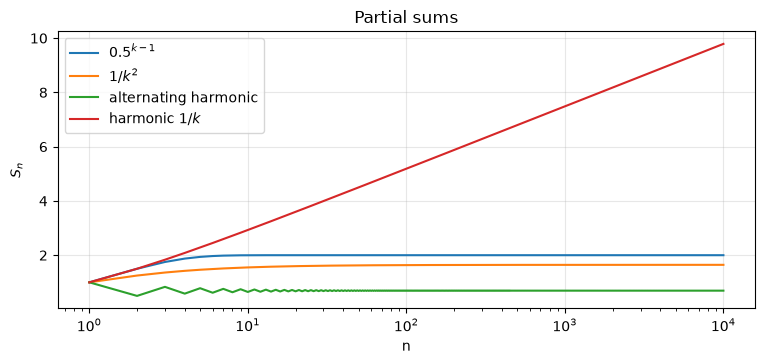

In [2]:
K = 10000
k = np.arange(1, K + 1)
geo = np.cumsum(0.5 ** (k - 1))
p2 = np.cumsum(1 / k**2)
alt = np.cumsum((-1.0) ** (k + 1) / k)
har = np.cumsum(1 / k)

print(f"geometric  S_{K} = {geo[-1]:.6f}   (limit 2)")
print(f"1/k^2      S_{K} = {p2[-1]:.6f}   (limit pi^2/6 = {np.pi**2/6:.6f})")
print(f"alt. harm. S_{K} = {alt[-1]:.6f}   (limit ln 2 = {np.log(2):.6f})")
print(f"harmonic   S_{K} = {har[-1]:.4f}   (grows like ln n + 0.5772 = {np.log(K)+0.5772:.4f})")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.semilogx(k, geo, label="$0.5^{k-1}$"); ax.semilogx(k, p2, label="$1/k^2$")
ax.semilogx(k, alt, label="alternating harmonic"); ax.semilogx(k, har, label="harmonic $1/k$")
ax.set(xlabel="n", ylabel="$S_n$", title="Partial sums"); ax.legend()
plt.show()

The geometric, $p=2$ and alternating series settle at $2$, $\pi^2/6$ and $\ln2$. The harmonic series keeps rising like $\ln n$, which is why $a_n\to0$ is necessary but not sufficient.

## Truncation error and persistence

The tail after $m$ terms is $r^{m+1}/(1-r)$. For $r=0.5$ a handful of terms suffices; for $r=0.99$ (a near-unit-root persistence) hundreds are needed.

r= 0.5: terms for tail<1e-3 =   10;  tail formula 9.77e-04, direct 9.77e-04
r= 0.9: terms for tail<1e-3 =   87;  tail formula 9.40e-04, direct 9.40e-04
r=0.99: terms for tail<1e-3 = 1145;  tail formula 9.95e-04, direct 9.95e-04


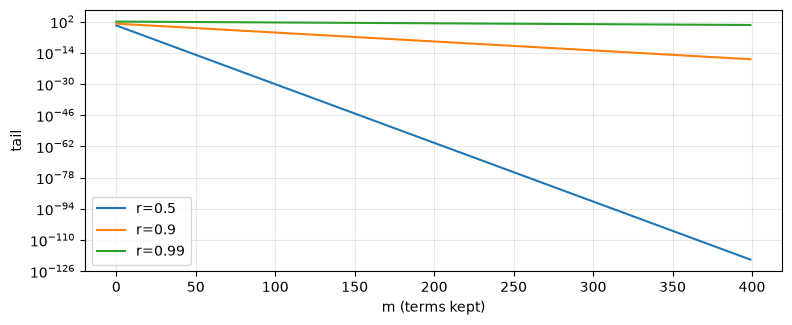

In [3]:
def tail(r, m): return r ** (m + 1) / (1 - r)
def terms_needed(r, tol=1e-3):
    m = 0
    while tail(r, m) > tol:
        m += 1
    return m

for r in (0.5, 0.9, 0.99):
    m = terms_needed(r)
    exact = 1 / (1 - r) - sum(r**j for j in range(m + 1))
    print(f"r={r:4}: terms for tail<1e-3 = {m:4d};  tail formula {tail(r, m):.2e}, direct {exact:.2e}")

m = np.arange(0, 400)
plt.figure(figsize=(9, 3.4))
for r in (0.5, 0.9, 0.99):
    plt.semilogy(m, tail(r, m), label=f"r={r}")
plt.xlabel("m (terms kept)"); plt.ylabel("tail"); plt.legend(); plt.show()

The number of terms needed grows from about 10 to about 87 to about 1145 as $r\to1$: a formally convergent expansion can still need a long history, the numerical counterpart of persistence.

## MA(1) inversion and mean-square convergence

For $X_t=Z_t+\beta Z_{t-1}$, $Z_t=\sum_{k\ge0}(-\beta)^kX_{t-k}$ and the truncation $S_n$ satisfies $E[(Z_t-S_n)^2]=\beta^{2(n+1)}\sigma_Z^2$ for $|\beta|<1$. We also check the autocovariances.

In [4]:
sigma_z, N = 1.0, 200_000
Z = rng.normal(0, sigma_z, N + 1)

for beta in (0.6, 1.2):
    X = Z[1:] + beta * Z[:-1]                      # X_t for t = 1..N
    print(f"beta={beta}:  Var={X.var():.3f} (theory {(1+beta**2)*sigma_z**2:.3f}), "
          f"gamma(1)={np.mean(X[1:]*X[:-1]):.3f} (theory {beta*sigma_z**2:.3f})")
    for n_ in (2, 5, 10, 20):
        t0 = 50                                      # evaluate for t >= 50 using the available lags
        idx = np.arange(t0, N)
        Sn = sum((-beta) ** j * X[idx - j] for j in range(n_ + 1))
        mse = np.mean((Z[1:][idx] - Sn) ** 2)
        print(f"   n={n_:2d}: empirical MSE {mse:12.4g}   theory {beta**(2*(n_+1))*sigma_z**2:12.4g}")

beta=0.6:  Var=1.356 (theory 1.360), gamma(1)=0.596 (theory 0.600)
   n= 2: empirical MSE      0.04658   theory      0.04666
   n= 5: empirical MSE     0.002173   theory     0.002177
   n=10: empirical MSE    1.314e-05   theory    1.316e-05
   n=20: empirical MSE    4.804e-10   theory    4.812e-10
beta=1.2:  Var=2.433 (theory 2.440), gamma(1)=1.191 (theory 1.200)
   n= 2: empirical MSE        2.981   theory        2.986
   n= 5: empirical MSE        8.901   theory        8.916
   n=10: empirical MSE        55.11   theory        55.21
   n=20: empirical MSE         2113   theory         2116


For $\beta=0.6$ the empirical truncation error matches $\beta^{2(n+1)}\sigma_Z^2$ and vanishes quickly; for $\beta=1.2$ the same formula grows with $n$, so the inverse expansion diverges. This is the invertibility condition: the root $B=-1/\beta$ must lie outside the unit circle, i.e. $|\beta|<1$.